# DBSCAN clustering

<a target="_blank" href="https://colab.research.google.com/github/changyaochen/MECE4520/blob/master/site/unsupervised-learning/04-dbscan-clustering.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"/></a>

In this notebook, we will use **DBSCAN** (Density-Based Spatial Clustering of Applications with Noise) to find clusters in a noisy concentric-circle dataset. The example shows a geometry that is not naturally described by compact centroids or a variance-minimizing hierarchical merge rule.

DBSCAN defines a cluster as a connected dense region. It needs no requested number of clusters, but it does require two density settings: a neighborhood radius `eps` and a minimum number of nearby observations, `min_samples`.

## 1. Create and inspect noisy concentric circles

We use a fixed `make_circles` sample. The colors in the right panel show the synthetic rings used to generate the data; **DBSCAN will receive only the two coordinate columns**. The sample is deliberately slightly noisy, so the two rings are not perfect mathematical circles.

Data shape: (100, 2) (samples, features)


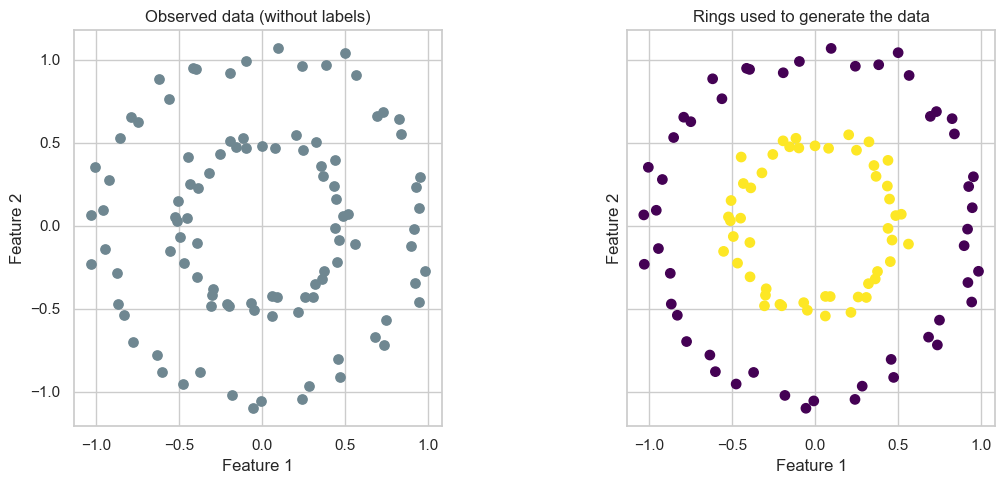

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.datasets import make_circles

sns.set_theme(style="whitegrid", context="notebook")

# These settings also generate the fixed data used by the exploration page.
X, generated_ring = make_circles(
    n_samples=100, factor=0.5, noise=0.05, random_state=170
)
print(f"Data shape: {X.shape} (samples, features)")

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
axes[0].scatter(X[:, 0], X[:, 1], s=45, color="#6f8791")
axes[0].set_title("Observed data (without labels)")
axes[1].scatter(X[:, 0], X[:, 1], c=generated_ring, cmap="viridis", s=45)
axes[1].set_title("Rings used to generate the data")
for ax in axes:
    ax.set(xlabel="Feature 1", ylabel="Feature 2")
    ax.set_aspect("equal", adjustable="box")
fig.tight_layout()
plt.show()

## 2. A compact-cluster merge rule is a poor match

Agglomerative clustering needs a linkage rule. Ward linkage merges groups to keep their within-cluster variation small, much like the compact-cluster preference of k-means. That is a poor geometric match for an inner ring and an outer ring: the result tends to divide the plane into compact sectors rather than separate the rings.

This does not mean every linkage rule gives the same answer. It means the linkage rule is a modeling choice, and this particular geometry motivates a different definition of a cluster.

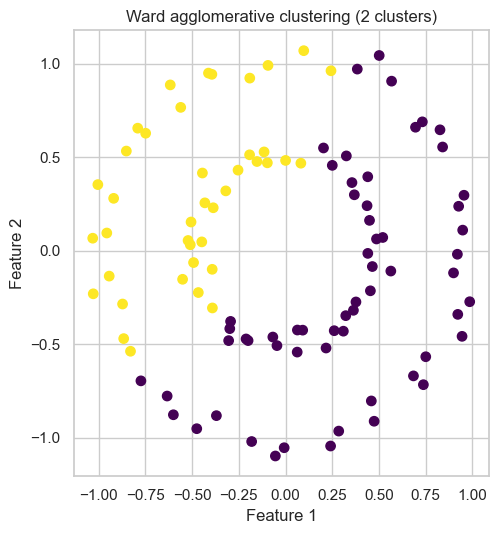

In [2]:
ward = AgglomerativeClustering(n_clusters=2, linkage="ward")
ward_labels = ward.fit_predict(X)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.scatter(X[:, 0], X[:, 1], c=ward_labels, cmap="viridis", s=45)
ax.set(
    title="Ward agglomerative clustering (2 clusters)",
    xlabel="Feature 1",
    ylabel="Feature 2",
)
ax.set_aspect("equal", adjustable="box")
fig.tight_layout()
plt.show()

## 3. Fit DBSCAN

For a point to be a **core point**, its `eps`-neighborhood must contain at least `min_samples` observations, including the point itself. DBSCAN expands a cluster outward through connected core points. A non-core point near a core point may join as a **border point**; a point not reached by any cluster is labeled **noise**.

The values below are useful for this standardized synthetic coordinate system. In a real application, the scale of the features directly affects the appropriate choice of `eps`.

Clusters found: 2
Core points: 97
Border points: 3
Noise points: 0


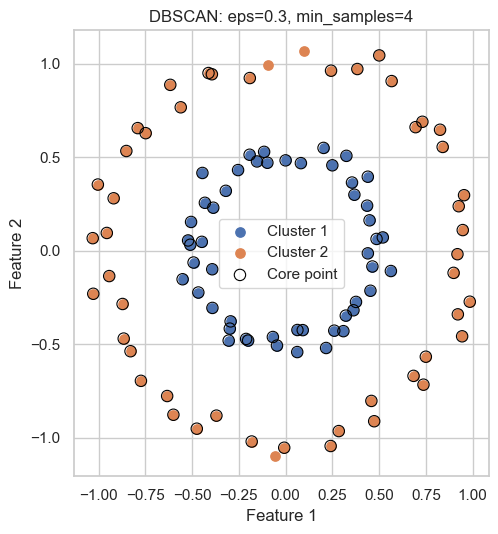

In [3]:
epsilon = 0.30
min_samples = 4

dbscan = DBSCAN(eps=epsilon, min_samples=min_samples)
dbscan_labels = dbscan.fit_predict(X)

core_mask = np.zeros(X.shape[0], dtype=bool)
core_mask[dbscan.core_sample_indices_] = True
noise_mask = dbscan_labels == -1
border_mask = ~core_mask & ~noise_mask
n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)

print(f"Clusters found: {n_clusters}")
print(f"Core points: {core_mask.sum()}")
print(f"Border points: {border_mask.sum()}")
print(f"Noise points: {noise_mask.sum()}")

fig, ax = plt.subplots(figsize=(6.5, 5.5))
for label in sorted(set(dbscan_labels) - {-1}):
    mask = dbscan_labels == label
    ax.scatter(X[mask, 0], X[mask, 1], s=45, label=f"Cluster {label + 1}")
if noise_mask.any():
    ax.scatter(X[noise_mask, 0], X[noise_mask, 1], s=45, color="#8d989e", label="Noise")
# An outline identifies points dense enough to be core points.
ax.scatter(X[core_mask, 0], X[core_mask, 1], s=67, facecolors="none", edgecolors="black", linewidths=0.8, label="Core point")
ax.set(
    title=f"DBSCAN: eps={epsilon}, min_samples={min_samples}",
    xlabel="Feature 1",
    ylabel="Feature 2",
)
ax.set_aspect("equal", adjustable="box")
ax.legend(loc="best")
fig.tight_layout()
plt.show()

## 4. Explore the expansion process

The fitted labels summarize the final result, but they hide how DBSCAN grows a cluster. Use the [DBSCAN exploration page](dbscan-explorer.qmd) to step through neighborhood inspections and expansion from core points. Try a smaller `eps` value to see rings fragment, or a larger one to see groups merge.

## Takeaways

- DBSCAN defines clusters as dense connected regions rather than compact groups around a centroid.
- `eps` sets the neighborhood radius; `min_samples` sets how many nearby observations are needed for a core point.
- DBSCAN can identify the nested, non-convex rings without being told that there are two clusters.
- Its result depends on the density settings, so feature scaling and parameter inspection remain important.

[← Return to Unsupervised learning](index.qmd)